# AIDA 2154 Final Project – 03 Baseline Classifier and Missing-Item Flags

**Data version 2** (`shared/synthetic-data/kit-cards/`), regions from notebook 02's frozen segmentation.

**Question:** Using the regions found in notebook 02, can a transparent colour-and-shape classifier name each region as one of the five kit items or "not a kit item", and how well do the resulting missing-item flags work on validation cards?

This is the project's baseline. The coordinator's goal is to catch kits with an item left off, so the main measure is **missing-item recall**, reported together with missing-item precision and the false missing-item flags that create unnecessary checks. A more complex model (notebook 04) will be compared with this baseline on the same split, the same training regions and the same measures.

**Use of the splits.** The classifier's regularisation strength is chosen by cross-validation within the training cards, grouped by card, with feature scaling fitted inside each fold. Validation evaluates the candidate pipeline, but it remains development evidence because it previously informed segmentation in notebook 02. Test images are not opened; the complete frozen pipeline will be evaluated on them once, at the end of the project.

All cards are computer-generated and contain no personal information.

In [1]:
import hashlib
import json
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from PIL import Image, ImageDraw
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

DATA_VERSION = "2"
SD = Path("../../../shared/synthetic-data")          # data version 2
KIT = SD / "kit-cards"
OUTPUT_DIR = Path("../outputs")
FIGURE_DIR = Path("../figures")
OUTPUT_DIR.mkdir(exist_ok=True)
FIGURE_DIR.mkdir(exist_ok=True)
SEED = 2026
ITEMS = ["access_badge", "safety_vest", "hard_hat", "laptop", "phone"]
NOT_KIT = "not_kit_item"
CLASSES = ITEMS + [NOT_KIT]
DEV_SPLITS = ["train", "validation"]  # only development images are read; metadata includes all splits

manifest = pd.read_csv(KIT / "manifest.csv", keep_default_na=False, na_values=[""])
objects = pd.read_csv(KIT / "icon_instances.csv", keep_default_na=False, na_values=[""])
settings = json.loads((OUTPUT_DIR / "segmentation_settings.json").read_text())      # frozen in notebook 02
regions_saved = pd.read_csv(OUTPUT_DIR / "regions_dev.csv", keep_default_na=False, na_values=[""])

# The frozen settings must still describe these exact inputs
sha = lambda path: hashlib.sha256(Path(path).read_bytes()).hexdigest()
dev_cards = manifest[manifest["split"].isin(DEV_SPLITS)].reset_index(drop=True)
dev_objects = objects[objects["split"].isin(DEV_SPLITS)].reset_index(drop=True)
image_records = [{"file_name": f, "sha256": sha(KIT / "images" / f)} for f in sorted(dev_cards["file_name"])]
recorded = settings["inputs_sha256"]
inputs_match = (recorded["manifest.csv"] == sha(KIT / "manifest.csv")
                and recorded["icon_instances.csv"] == sha(KIT / "icon_instances.csv")
                and recorded["generation_info.json"] == sha(KIT / "outputs/generation_info.json")
                and recorded["development_images (file names and contents, train + validation, sorted by name)"]
                == hashlib.sha256(json.dumps(image_records, sort_keys=True).encode()).hexdigest())
assert inputs_match, "The inputs no longer match the frozen segmentation settings from notebook 02"

# Saved region identities and card links
card_splits = manifest.set_index("card_id")["split"]
assert not regions_saved.duplicated(["card_id", "region"]).any(), "Duplicate saved region identifiers"
assert regions_saved["card_id"].isin(dev_cards["card_id"]).all(), "A saved region belongs to a non-development or unknown card"
assert regions_saved["split"].eq(regions_saved["card_id"].map(card_splits)).all(), "A saved region has the wrong split"

# The segmentation must be rebuilt with the same software versions it was frozen with
versions = settings["package_versions"]
assert cv2.__version__ == versions["opencv"], f"OpenCV {cv2.__version__} differs from the frozen {versions['opencv']}"
assert np.__version__ == versions["numpy"], f"NumPy {np.__version__} differs from the frozen {versions['numpy']}"

print(f"Data version {DATA_VERSION}; frozen segmentation: {settings['chosen']['name']}")
print(f"Development cards: {(dev_cards['split'] == 'train').sum()} training, {(dev_cards['split'] == 'validation').sum()} validation; "
      f"saved regions: {len(regions_saved)}")
print("Inputs match the frozen segmentation settings:", inputs_match)

Data version 2; frozen segmentation: masked | gray > 9 | close 11
Development cards: 360 training, 120 validation; saved regions: 1243
Inputs match the frozen segmentation settings: True


## A. Rebuilding each region's pixels

Notebook 02 saved each region's box, but colour and shape features need its **predicted foreground pixels** (the connected-component mask) rather than the entire box or the recorded object box. These masks may include noise or paper and may omit parts of a drawing. This section reruns the frozen segmentation exactly as recorded in `segmentation_settings.json` and keeps each region's mask.

As a provenance check, the rebuilt regions must match notebook 02's saved regions box for box, in region order, on every card. If they don't, the notebook stops, because the features would then describe different regions from the ones notebook 02 evaluated.

In [2]:
rows_a, rows_b = settings["content_area"]["rows"]           # inclusive bounds
cols_a, cols_b = settings["content_area"]["columns"]
CONTENT = (slice(rows_a, rows_b + 1), slice(cols_a, cols_b + 1))
chosen = settings["chosen"]
mb = settings["masked_background"]
assert chosen["background"] == "masked" and chosen["measure"] == "gray", "This notebook rebuilds the masked grayscale setting"
GRAY_WEIGHTS = np.array([0.114, 0.587, 0.299], dtype=np.float32)   # OpenCV loads images as blue-green-red
OPEN = int(settings["opening"].split(" x ")[0])


def segment(path):
    # The frozen pipeline; returns the denoised content (BGR), the paper estimate, the component label image and boxes
    image = cv2.imread(str(path))
    if image is None:
        raise ValueError(f"Could not open image: {path}")
    content = cv2.medianBlur(image, settings["median_filter"])[CONTENT].astype(np.float32)
    sigma = settings["background_sigma"]
    gaussian = cv2.GaussianBlur(content, (0, 0), sigma)
    prelim = np.linalg.norm(content - gaussian, axis=2) > mb["preliminary_colour_threshold"]
    d = int(mb["preliminary_mask_dilation"].split(" x ")[0])
    prelim = cv2.dilate(prelim.astype(np.uint8), np.ones((d, d), np.uint8)).astype(bool)
    remaining = (~prelim).astype(np.float32)
    weight = cv2.GaussianBlur(remaining, (0, 0), sigma)
    paper = cv2.GaussianBlur(content * remaining[..., None], (0, 0), sigma) / np.maximum(weight, mb["minimum_background_weight"])[..., None]
    paper = np.where(weight[..., None] > mb["minimum_background_weight"], paper, gaussian)
    diff = np.abs((content - paper) @ GRAY_WEIGHTS)
    mask = (diff > chosen["threshold"]).astype(np.uint8)
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, np.ones((OPEN, OPEN), np.uint8))
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (chosen["close"],) * 2))
    _, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=settings["connectivity"])
    keep = [k for k in range(1, len(stats)) if stats[k][4] >= settings["min_region_pixels"]]
    boxes = [(int(stats[k][0]) + CONTENT[1].start, int(stats[k][1]) + CONTENT[0].start,
              int(stats[k][0] + stats[k][2]) + CONTENT[1].start, int(stats[k][1] + stats[k][3]) + CONTENT[0].start) for k in keep]
    return content, paper, labels, keep, boxes


segmented = {}
mismatched_cards = []
for card in dev_cards.itertuples():
    content, paper, labels, keep, boxes = segment(KIT / "images" / card.file_name)
    saved_card = regions_saved[regions_saved["card_id"] == card.card_id].sort_values("region")
    assert saved_card["region"].tolist() == list(range(len(saved_card))), f"Unexpected region numbering on {card.card_id}"
    saved_boxes = list(saved_card[["x0", "y0", "x1", "y1"]].itertuples(index=False, name=None))
    if boxes != saved_boxes:
        mismatched_cards.append(card.card_id)
    segmented[card.card_id] = (content, paper, labels, keep)
regions_reproduced = not mismatched_cards
print(f"Rebuilt regions on {len(segmented)} cards; cards whose regions differ from notebook 02: {len(mismatched_cards)}")
assert regions_reproduced, f"Rebuilt regions differ from notebook 02 on {mismatched_cards[:5]}"

Rebuilt regions on 480 cards; cards whose regions differ from notebook 02: 0


## B. Colour and shape features

Each region is described by 18 numbers, computed only from its predicted foreground pixels (the rebuilt component mask) and the local paper estimate. No label, matching outcome or recorded object attribute is used as a feature; those are used only as training targets and for evaluation.

**Colour (5):** the average difference between the region's pixels and the paper behind them in CIELAB colour space: lightness (**dL**, negative when the region is darker than the paper, positive when lighter), green–red (**da**) and blue–yellow (**db**); the average **saturation** (OpenCV's 0–255 scale); and the share of pixels **lighter than the paper** (a proportion from 0 to 1). Colour differences use OpenCV's 8-bit Lab representation, with lightness differences rescaled to approximately −100 to 100. They are feature measurements, not a calibrated perceptual colour-difference score.

**Shape (13):** **width**, **height** and **aspect ratio** of the predicted component's bounding box; **area** (foreground pixels); **fill** (area divided by box area); **solidity** (foreground pixels divided by the pixels inside the region's convex hull, so it lies between 0 and 1); and the seven **Hu moments** of the region's mask. Hu moments are transformed using −sign(h) × log10(|h| + 10⁻³⁰) to reduce their numerical range. They are designed to be rotation-invariant, although pixel sampling and segmentation can change their values.

Larger regions naturally have larger widths and areas; the classifier sees all features after scaling to comparable ranges.

In [3]:
FEATURES = ["dL", "da", "db", "saturation", "lighter_share", "width", "height", "aspect", "area", "fill", "solidity"] + \
           [f"hu{i}" for i in range(1, 8)]


def region_features(content, paper, labels, k):
    comp = labels == k
    ys, xs = np.nonzero(comp)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    pix = content[comp].astype(np.uint8).reshape(-1, 1, 3)
    bg = paper[comp].clip(0, 255).astype(np.uint8).reshape(-1, 1, 3)
    lab_p = cv2.cvtColor(pix, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
    lab_b = cv2.cvtColor(bg, cv2.COLOR_BGR2LAB).reshape(-1, 3).astype(np.float32)
    delta = (lab_p - lab_b).mean(axis=0)
    hsv = cv2.cvtColor(pix, cv2.COLOR_BGR2HSV).reshape(-1, 3).astype(np.float32)
    sub = comp[y0:y1, x0:x1].astype(np.uint8)
    contours, _ = cv2.findContours(sub, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    hull = cv2.convexHull(np.vstack(contours))
    hull_mask = np.zeros_like(sub)
    cv2.fillConvexPoly(hull_mask, hull, 1)
    hull_area = int(hull_mask.sum())                 # pixel count, like area, so solidity stays between 0 and 1
    hu = cv2.HuMoments(cv2.moments(sub, binaryImage=True)).ravel()
    hu = -np.sign(hu) * np.log10(np.abs(hu) + 1e-30)
    area, w, h = int(comp.sum()), int(x1 - x0), int(y1 - y0)
    return dict(zip(FEATURES, [delta[0] * 100 / 255, delta[1], delta[2], hsv[:, 1].mean(), (lab_p[:, 0] > lab_b[:, 0]).mean(),
                               w, h, w / h, area, area / (w * h), area / max(hull_area, 1), *hu]))


feature_rows = []
for card_id, (content, paper, labels, keep) in segmented.items():
    for region, k in enumerate(keep):
        feature_rows.append({"card_id": card_id, "region": region, **region_features(content, paper, labels, k)})
features = pd.DataFrame(feature_rows)
assert len(FEATURES) == 18, "The Markdown describes 18 features"
data = regions_saved.merge(features, on=["card_id", "region"], how="left", validate="one_to_one")
assert len(data) == len(regions_saved) and data[FEATURES].notna().all().all(), "Every saved region needs a full set of features"

# Reference label for each region, where one is unambiguous
REFERENCE = {"kit_item_clean": "object", "kit_item_poor_fit": "object", "kit_item_split_part": "object",
             "background_clean": NOT_KIT, "background_poor_fit": NOT_KIT, "background_split_part": NOT_KIT, "unmatched": NOT_KIT}
data["reference"] = [(r.object if REFERENCE.get(r.label_group) == "object" else REFERENCE.get(r.label_group))
                     for r in data.itertuples()]
data["training_region"] = (data["split"] == "train") & data["label_group"].isin(["kit_item_clean", "background_clean", "unmatched"])
assert np.isfinite(data[FEATURES].to_numpy(dtype=float)).all(), "Features contain missing or infinite values"
assert data.loc[data["training_region"], "reference"].isin(CLASSES).all(), "Every training region needs an allowed reference class"
assert data["solidity"].between(0, 1).all(), "Solidity must be between 0 and 1"
data[["card_id", "split", "region", "label_group", "reference", "training_region"] + FEATURES].to_csv(
    OUTPUT_DIR / "region_features_dev.csv", index=False)          # full precision
print(f"Features for {len(data)} regions; training regions: {int(data['training_region'].sum())}")
print("Median of selected features by class (training regions):")
display(data[data["training_region"]].groupby("reference")[["dL", "da", "db", "saturation", "lighter_share", "aspect", "fill"]]
        .median().astype(float).reindex(CLASSES).round(2))

Features for 1243 regions; training regions: 916
Median of selected features by class (training regions):


,dL,da,db,saturation,lighter_share,aspect,fill
reference,,,,,,,
access_badge,-21.52,-7.75,1.47,64.86,0.01,0.71,0.73
safety_vest,-7.81,-5.25,29.82,89.24,0.00,0.92,0.81
hard_hat,-7.55,-0.49,0.59,10.38,0.00,1.68,0.61
laptop,-26.34,0.17,-7.70,26.77,0.00,1.17,0.79
phone,-26.20,0.22,-6.02,19.77,0.00,0.56,0.79
not_kit_item,-25.24,4.01,-7.51,48.49,0.00,0.87,0.78


## C. The classifier

**Model:** multinomial logistic regression on standardised features. Balanced class weights give each class approximately equal total weight during fitting. This is a fixed modelling choice; macro F1 gives each class equal importance during model selection. Scaling is fitted inside each cross-validation fold, as part of the same pipeline.

**Training regions:** training-card regions labelled `kit_item_clean` (with their item), `background_clean` and `unmatched` (as "not a kit item"). Poor-fit, split, merged and ambiguous regions are left out to give a conservative starting point, so the classifier trains on cleaner crops than it meets in evaluation. Notebook 04's model will train on exactly the same regions.

**Choosing the regularisation strength:** C is chosen from {0.01, 0.1, 1, 10, 100} by 5-fold cross-validation **within the training cards**, grouped by card so a card's regions never sit on both sides of a fold. C is selected using **macro F1** across the six classes, calculated from the pooled out-of-fold predictions across all training regions (one score per C, not an average of five fold scores), so accuracy on the most common class can't dominate. Ties go to the smaller C (stronger regularisation). The same five folds are used for every C. Validation is not used for this choice.

The fitted pipeline, settings and model fingerprint are saved for downstream use (`outputs/baseline_classifier.joblib` and `outputs/classifier_settings.json`), together with the exact training regions (`outputs/classifier_training_regions.csv`) so notebook 04 can verify it uses the same examples. Once the final method is frozen, test evaluation loads the saved pipeline without retraining it.

The coefficients show which features the model associates with each class; the table lists the three features with the largest positive coefficients for each class (on the standardised scale). They show associations with each class's score in these generated cards, not causes, and they are not a complete feature-importance ranking, especially because some features (such as width, area and fill) are correlated.

In [4]:
import joblib                      # saves the fitted model for the final test evaluation

train = data[data["training_region"]].reset_index(drop=True)
X_train, y_train, groups = train[FEATURES].to_numpy(), train["reference"].to_numpy(), train["card_id"].to_numpy()
C_GRID = [0.01, 0.1, 1, 10, 100]
make_model = lambda C: make_pipeline(StandardScaler(), LogisticRegression(C=C, class_weight="balanced", max_iter=5000))

# The same five card-grouped folds for every C, checked for separation and class coverage
assert set(y_train) == set(CLASSES), "Training data must contain all six classes"
folds = list(GroupKFold(n_splits=5).split(X_train, y_train, groups))
for fit_idx, held_idx in folds:
    assert set(groups[fit_idx]).isdisjoint(set(groups[held_idx])), "A card appears on both sides of a fold"
    assert set(y_train[fit_idx]) == set(CLASSES), "A fitting fold is missing a class"

cv_rows = []
for C in C_GRID:
    pred = cross_val_predict(make_model(C), X_train, y_train, cv=folds)
    cv_rows.append({"C": C, "macro_f1": f1_score(y_train, pred, average="macro", labels=CLASSES),
                    "accuracy": (pred == y_train).mean()})
cv_results = pd.DataFrame(cv_rows)
best_C = cv_results.sort_values(["macro_f1", "C"], ascending=[False, True]).iloc[0]["C"]
cv_results.to_csv(OUTPUT_DIR / "classifier_cv_train.csv", index=False)
print(f"Training regions by class: {train['reference'].value_counts().reindex(CLASSES).to_dict()}")
display(cv_results.round(4))
print(f"Chosen C (highest cross-validated macro F1 on training cards): {best_C:g}")

model = make_model(best_C).fit(X_train, y_train)
coef = pd.DataFrame(model[-1].coef_, index=model[-1].classes_, columns=FEATURES).reindex(CLASSES)
coef.to_csv(OUTPUT_DIR / "classifier_coefficients.csv")          # full precision
top = pd.DataFrame({cls: coef.loc[cls].sort_values(ascending=False).index[:3] for cls in CLASSES}, index=["1st", "2nd", "3rd"]).T
print("Features with the largest positive coefficients for each class (standardised scale):")
display(top)
MODEL_PATH = OUTPUT_DIR / "baseline_classifier.joblib"
joblib.dump(model, MODEL_PATH)
train[["card_id", "region", "reference"]].to_csv(OUTPUT_DIR / "classifier_training_regions.csv", index=False)
_ = (OUTPUT_DIR / "classifier_settings.json").write_text(json.dumps({
    "data_version": DATA_VERSION, "model": "multinomial logistic regression, standardised features, balanced class weights",
    "features": FEATURES, "n_features": len(FEATURES), "classes": CLASSES, "C_grid": C_GRID, "chosen_C": float(best_C),
    "selection": "5-fold GroupKFold by card within training; macro F1 over six classes; ties to smaller C",
    "training_region_rule": "train split; label groups kit_item_clean, background_clean, unmatched",
    "segmentation_settings_sha256": sha(OUTPUT_DIR / "segmentation_settings.json"),
    "region_features_sha256": sha(OUTPUT_DIR / "region_features_dev.csv"),
    "regions_dev_sha256": sha(OUTPUT_DIR / "regions_dev.csv"),
    "training_regions_file": "classifier_training_regions.csv", "training_regions": int(len(train)),
    "training_regions_sha256": sha(OUTPUT_DIR / "classifier_training_regions.csv"),
    "estimator_parameters": {k: v for k, v in model[-1].get_params().items() if isinstance(v, (int, float, str, bool, type(None)))},
    "model_file": MODEL_PATH.name, "model_sha256": sha(MODEL_PATH),
    "package_versions": {"scikit-learn": sklearn.__version__, "joblib": joblib.__version__, "opencv": cv2.__version__,
                         "numpy": np.__version__}}, indent=2) + "\n")

Training regions by class: {'access_badge': 188, 'safety_vest': 177, 'hard_hat': 175, 'laptop': 88, 'phone': 88, 'not_kit_item': 200}


,C,macro_f1,accuracy
0,0.01,0.8884,0.8974
1,0.10,0.9509,0.9541
2,1.00,0.9982,0.9978
3,10.00,0.9991,0.9989
4,100.00,0.9991,0.9989


Chosen C (highest cross-validated macro F1 on training cards): 10
Features with the largest positive coefficients for each class (standardised scale):


,1st,2nd,3rd
access_badge,lighter_share,saturation,hu5
safety_vest,dL,db,saturation
hard_hat,aspect,lighter_share,db
laptop,hu2,aspect,width
phone,height,db,hu4
not_kit_item,solidity,da,hu4


## D. Region results on validation

Every validation region is classified. The confusion matrix and per-class measures use the regions with an unambiguous reference label: kit-item regions (clean, poor fit or split part) labelled with their item, and background and unmatched regions as "not a kit item". Merged and ambiguous regions have no single reference label, so they are left out of this table but still pass through the card-level evaluation in section E. (With the frozen segmentation there are none on validation.)

Each saved prediction also records `predicted_class_score`, the model's highest class probability for that region. It is uncalibrated (and affected by the class weighting), so it is not a measured confidence that the prediction is correct. No decision in this notebook uses it.

In [5]:
data["predicted"] = model.predict(data[FEATURES].to_numpy())
data["predicted_class_score"] = model.predict_proba(data[FEATURES].to_numpy()).max(axis=1)   # uncalibrated
val = data[data["split"] == "validation"]
scored_regions = val[val["reference"].notna()]
cm = pd.DataFrame(confusion_matrix(scored_regions["reference"], scored_regions["predicted"], labels=CLASSES),
                  index=pd.Index(CLASSES, name="reference"), columns=pd.Index(CLASSES, name="predicted"))
p, r, f, n = precision_recall_fscore_support(scored_regions["reference"], scored_regions["predicted"], labels=CLASSES, zero_division=0)
per_class = pd.DataFrame({"regions": n, "precision": p, "recall": r, "f1": f}, index=pd.Index(CLASSES, name="class"))
cm.to_csv(OUTPUT_DIR / "region_confusion_validation.csv")
per_class.round(4).to_csv(OUTPUT_DIR / "region_metrics_validation.csv")
data[["card_id", "split", "region", "label_group", "reference", "predicted", "predicted_class_score"]].to_csv(
    OUTPUT_DIR / "region_predictions_dev.csv", index=False)
print(f"Validation regions: {len(val)}; with a reference label: {len(scored_regions)}; "
      f"correct: {int((scored_regions['reference'] == scored_regions['predicted']).sum())}; "
      f"macro F1: {f1_score(scored_regions['reference'], scored_regions['predicted'], average='macro', labels=CLASSES):.3f}")
display(cm)
display(per_class.round(3))

Validation regions: 322; with a reference label: 322; correct: 319; macro F1: 0.992


predicted,access_badge,safety_vest,hard_hat,laptop,phone,not_kit_item
reference,,,,,,
access_badge,65,0,0,0,0,0
safety_vest,0,55,0,0,0,0
hard_hat,0,0,62,0,0,0
laptop,0,0,0,31,0,0
phone,0,0,0,0,25,0
not_kit_item,2,0,0,1,0,81


,regions,precision,recall,f1
class,,,,
access_badge,65,0.970,1.000,0.985
safety_vest,55,1.000,1.000,1.000
hard_hat,62,1.000,1.000,1.000
laptop,31,0.969,1.000,0.984
phone,25,1.000,1.000,1.000
not_kit_item,84,1.000,0.964,0.982


## E. Card decisions and missing-item flags (validation)

**From regions to decisions.** An item is **detected** on a card if any region on that card is classified as that item. Then, for each card and item, using the recorded expectations:

| Recorded expectation | Detected | Not detected |
|:---|:---|:---|
| Expected, and drawn on the card | Correct | **False missing-item flag** (a present item wasn't found) |
| Expected, but left off (an actual omission) | **Missed omission** (no flag, because something was wrongly detected as that item) | **Correct missing-item flag** |
| Known not to be expected | **Unexpected detection** | Correct |
| Unknown expectation | Needs review (not scored) | Needs review (not scored) |

**Measures, fixed before any result was seen:**
- **Missing-item recall** (main): correct missing-item flags ÷ actual omissions.
- **Missing-item precision:** correct missing-item flags ÷ all missing-item flags.
- **False-flag rate:** false missing-item flags ÷ expected items that are actually present.
- **Unexpected detections:** count of detections of items known not to be expected.
- **Cards needing a coordinator check:** any missing-item flag, unexpected detection, or unknown expectation.
- **Completely correct card:** every known expected item's missing/present decision is correct and there is no unexpected detection. Cards with an unknown expectation are reported separately, because one of their decisions can't be scored.

In [6]:
detected = val[val["predicted"] != NOT_KIT].groupby("card_id")["predicted"].agg(set)
val_cards = dev_cards[dev_cards["split"] == "validation"]
decision_rows = []
for card in val_cards.itertuples():
    found = detected.get(card.card_id, set())
    for item in ITEMS:
        known = getattr(card, f"expectation_known_{item}") == 1
        expected = getattr(card, f"expected_{item}") == 1
        present = getattr(card, f"present_{item}") == 1
        omitted = getattr(card, f"omitted_{item}") == 1
        hit = item in found
        if not known:
            outcome = "needs_review"
        elif expected and present:
            outcome = "correct_present" if hit else "false_missing_flag"
        elif expected and omitted:
            outcome = "missed_omission" if hit else "correct_missing_flag"
        else:
            outcome = "unexpected_detection" if hit else "correct_not_expected"
        decision_rows.append({"card_id": card.card_id, "item": item, "known": known, "expected": expected,
                              "present": present, "omitted": omitted, "detected": hit, "outcome": outcome,
                              "blur_radius": card.blur_radius, "jpeg_quality": card.jpeg_quality})
decisions = pd.DataFrame(decision_rows)
decisions.to_csv(OUTPUT_DIR / "card_item_decisions_validation.csv", index=False)

count = lambda o: int((decisions["outcome"] == o).sum())
tp, fn, fp = count("correct_missing_flag"), count("missed_omission"), count("false_missing_flag")
present_expected = count("correct_present") + fp
per_card = decisions.groupby("card_id").agg(
    any_flag=("outcome", lambda s: s.isin(["correct_missing_flag", "false_missing_flag"]).any()),
    unexpected=("outcome", lambda s: (s == "unexpected_detection").any()),
    needs_review=("outcome", lambda s: (s == "needs_review").any()),
    all_correct=("outcome", lambda s: s.isin(["correct_present", "correct_missing_flag", "correct_not_expected", "needs_review"]).all()))
per_card["needs_check"] = per_card["any_flag"] | per_card["unexpected"] | per_card["needs_review"]
summary = pd.Series({
    "actual omissions": tp + fn, "correct missing-item flags": tp, "missed omissions": fn,
    "missing-item recall": tp / (tp + fn) if tp + fn else np.nan, "false missing-item flags": fp,
    "missing-item precision": tp / (tp + fp) if tp + fp else np.nan,
    "expected items actually present": present_expected, "false-flag rate": fp / present_expected if present_expected else np.nan,
    "unexpected detections": count("unexpected_detection"), "decisions needing review (unknown expectation)": count("needs_review"),
    "cards": len(per_card), "cards needing a coordinator check": int(per_card["needs_check"].sum()),
    "share of cards needing a check": per_card["needs_check"].mean(),
    "cards with all expectations known": int((~per_card["needs_review"]).sum()),
    "  of these, completely correct": int((per_card["all_correct"] & ~per_card["needs_review"] & ~per_card["unexpected"]).sum()),
    "  share completely correct": (per_card["all_correct"] & ~per_card["unexpected"])[~per_card["needs_review"]].mean(),
    "cards with an unknown expectation": int(per_card["needs_review"].sum()),
    "  of these, all scored decisions correct": int((per_card["all_correct"] & per_card["needs_review"] & ~per_card["unexpected"]).sum()),
}, name="validation", dtype=object)                 # object dtype keeps counts as whole numbers
summary.to_frame().to_csv(OUTPUT_DIR / "missing_item_summary_validation.csv")
display(summary.to_frame().map(lambda v: f"{v:.3f}" if isinstance(v, float) else v))

by_item = decisions[decisions["known"]].pivot_table(index="item", columns="outcome", values="card_id", aggfunc="count",
                                                     fill_value=0).reindex(ITEMS)
for col in ["correct_missing_flag", "missed_omission", "false_missing_flag", "correct_present", "unexpected_detection"]:
    if col not in by_item:
        by_item[col] = 0
by_item["omission_recall"] = by_item["correct_missing_flag"] / (by_item["correct_missing_flag"] + by_item["missed_omission"]).replace(0, np.nan)
by_item["false_flag_rate"] = by_item["false_missing_flag"] / (by_item["false_missing_flag"] + by_item["correct_present"]).replace(0, np.nan)
by_item = by_item[["correct_missing_flag", "missed_omission", "omission_recall", "false_missing_flag", "correct_present",
                   "false_flag_rate", "unexpected_detection"]]
by_item.round(3).to_csv(OUTPUT_DIR / "missing_item_by_item_validation.csv")
print("By item (cards where the item's expectation is known):")
display(by_item.round(3))

,validation
actual omissions,43
correct missing-item flags,43
missed omissions,0
missing-item recall,1.000
false missing-item flags,0
missing-item precision,1.000
expected items actually present,238
false-flag rate,0.000
unexpected detections,1
decisions needing review (unknown expectation),4


By item (cards where the item's expectation is known):


outcome,correct_missing_flag,missed_omission,omission_recall,false_missing_flag,correct_present,false_flag_rate,unexpected_detection
item,,,,,,,
access_badge,12,0,1.0,0,65,0.0,1
safety_vest,14,0,1.0,0,55,0.0,0
hard_hat,7,0,1.0,0,62,0.0,0
laptop,4,0,1.0,0,31,0.0,0
phone,6,0,1.0,0,25,0.0,0


## F. Where recognition fails: present items by appearance

Size, contrast and drawing style exist only for items that were actually drawn, so this section looks at **present** items: for each drawn kit item on a validation card, whether it was recognised (some region on its card was classified as that item, which is what avoids a false missing-item flag). Here, "recognised" means that the pipeline reported the item somewhere on its card. It does not independently establish that the region containing that particular object was classified correctly; section D reports region-level classification separately. Faint hard hats and vests get a separate look, as asked for in the instructor's feedback. Omitted items have no drawn appearance, so omission results stay by item type in section E.

In [7]:
drawn = dev_objects[(dev_objects["split"] == "validation") & (dev_objects["role"] == "kit_item")].copy()
drawn["recognised"] = [obj in detected.get(c, set()) for c, obj in zip(drawn["card_id"], drawn["object"])]
ORDERS = {"object": ITEMS, "style": [f"{i} ({s})" for i in ITEMS for s in ["a", "b"]],
          "size_band": ["small", "medium", "large"], "contrast_band": ["low", "medium", "high"]}
drawn["style_key"] = drawn["object"] + " (" + drawn["style"] + ")"
for by, col in [("object", "object"), ("style", "style_key"), ("size_band", "size_band"), ("contrast_band", "contrast_band")]:
    t = drawn.groupby(col)["recognised"].agg(items="size", recognised="sum").reindex(ORDERS[by]).fillna(0).astype(int)
    t["not_recognised"] = t["items"] - t["recognised"]
    t["recognised_%"] = (100 * t["recognised"] / t["items"]).round(1)
    t.to_csv(OUTPUT_DIR / f"present_item_recognition_by_{by}_validation.csv")
    display(t)

faint = drawn[drawn["object"].isin(["hard_hat", "safety_vest"]) & (drawn["contrast_band"] == "low")]
faint_table = faint.groupby(["object", "style"])["recognised"].agg(items="size", recognised="sum")
faint_table.to_csv(OUTPUT_DIR / "faint_hats_vests_validation.csv")
print("Low-contrast hard hats and safety vests (validation):")
display(faint_table)
not_recognised = drawn[~drawn["recognised"]][["card_id", "object", "style", "size_band", "contrast", "contrast_band"]]
not_recognised.to_csv(OUTPUT_DIR / "present_items_not_recognised_validation.csv", index=False)
print(f"Present items not recognised: {len(not_recognised)}")
if len(not_recognised):
    display(not_recognised.set_index("card_id"))

,items,recognised,not_recognised,recognised_%
object,,,,
access_badge,65,65,0,100.0
safety_vest,55,55,0,100.0
hard_hat,62,62,0,100.0
laptop,31,31,0,100.0
phone,25,25,0,100.0


,items,recognised,not_recognised,recognised_%
style_key,,,,
access_badge (a),29,29,0,100.0
access_badge (b),36,36,0,100.0
safety_vest (a),33,33,0,100.0
safety_vest (b),22,22,0,100.0
hard_hat (a),31,31,0,100.0
hard_hat (b),31,31,0,100.0
laptop (a),14,14,0,100.0
laptop (b),17,17,0,100.0
phone (a),10,10,0,100.0


,items,recognised,not_recognised,recognised_%
size_band,,,,
small,50,50,0,100.0
medium,92,92,0,100.0
large,96,96,0,100.0


,items,recognised,not_recognised,recognised_%
contrast_band,,,,
low,56,56,0,100.0
medium,105,105,0,100.0
high,77,77,0,100.0


Low-contrast hard hats and safety vests (validation):


items  recognised
object      style                   
hard_hat    a          7           7
            b         12          12
safety_vest a         10          10
            b          6           6

Present items not recognised: 0


## G. Success and failure examples (validation)

Each panel shows a validation card with every found region outlined and numbered (green when the prediction matches the reference label, red when it doesn't, grey for regions without a single reference); the legend under each card gives each number's prediction. The title gives the card's missing-item decisions. One card is shown for each kind of outcome that actually occurs, picked reproducibly: a completely correct card, and cards with a false missing-item flag, a missed omission, or an unexpected detection, if any. These are illustrative, not a representative sample; section E shows how often each happens.

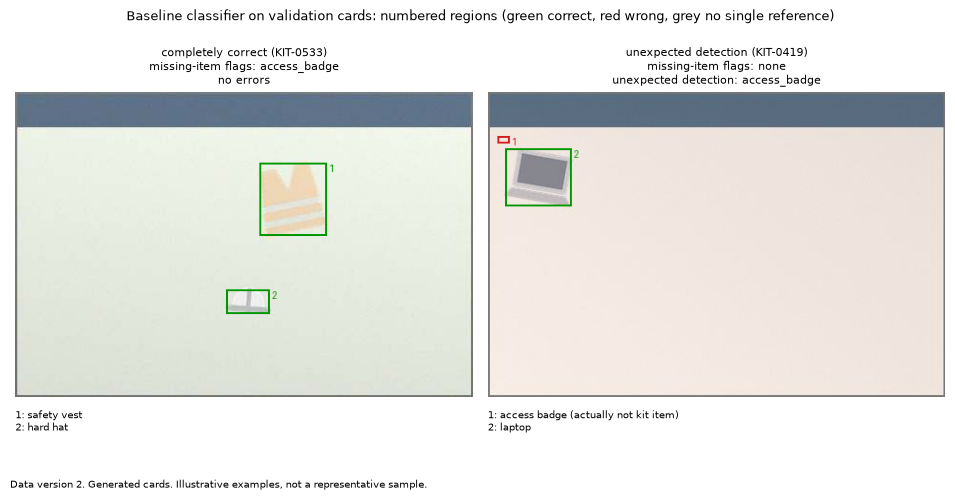

In [8]:
example_rng = np.random.default_rng(SEED)
files_by_card = manifest.set_index("card_id")["file_name"]
complete = per_card[per_card["all_correct"] & ~per_card["needs_review"] & ~per_card["unexpected"]].index
panels = []
if len(complete):
    panels.append(("completely correct", list(complete)))
for o in ["false_missing_flag", "missed_omission", "unexpected_detection"]:
    cards_with = decisions.loc[decisions["outcome"] == o, "card_id"].unique().tolist()
    if cards_with:
        panels.append((o.replace("_", " "), cards_with))
assert panels, "No example cards to show"
fig, axes = plt.subplots(1, len(panels), figsize=(4.8 * len(panels), 4.6))
axes = np.atleast_1d(axes)
example_rows = []
for ax, (title, pool) in zip(axes, panels):
    card_id = pool[int(example_rng.integers(len(pool)))]
    img = Image.open(KIT / "images" / files_by_card[card_id]).convert("RGB")
    draw = ImageDraw.Draw(img)
    legend = []
    for number, r in enumerate(val[val["card_id"] == card_id].itertuples(), start=1):
        colour = (130, 130, 130) if pd.isna(r.reference) else ((0, 150, 0) if r.reference == r.predicted else (210, 30, 30))
        draw.rectangle([r.x0, r.y0, r.x1 - 1, r.y1 - 1], outline=colour, width=2)
        draw.text((r.x1 + 2, r.y0), str(number), fill=colour)
        legend.append(f"{number}: {r.predicted.replace('_', ' ')}" + ("" if r.reference == r.predicted else f" (actually {str(r.reference).replace('_', ' ')})"))
    ax.imshow(img)
    ax.axis("off")
    ax.text(0.0, -0.04, "\n".join(legend), transform=ax.transAxes, va="top", fontsize=7)
    d = decisions[decisions["card_id"] == card_id]
    flags = ", ".join(d.loc[d["outcome"].isin(["correct_missing_flag", "false_missing_flag"]), "item"]) or "none"
    problems = "; ".join(f"{o.replace('_', ' ')}: {i}" for o, i in zip(d["outcome"], d["item"])
                         if o in ["false_missing_flag", "missed_omission", "unexpected_detection"]) or "no errors"
    ax.set_title(f"{title} ({card_id})\nmissing-item flags: {flags}\n{problems}", fontsize=8)
    example_rows.append({"example": title, "card_id": card_id, "flags": flags, "errors": problems})
fig.suptitle("Baseline classifier on validation cards: numbered regions (green correct, red wrong, grey no single reference)", fontsize=9)
fig.text(0.01, -0.06, "Data version 2. Generated cards. Illustrative examples, not a representative sample.", fontsize=7)
fig.tight_layout()
fig.savefig(FIGURE_DIR / "baseline_examples_validation.png", dpi=150, bbox_inches="tight")
plt.show()
pd.DataFrame(example_rows).to_csv(OUTPUT_DIR / "baseline_examples_validation.csv", index=False)

## H. Checks

In [9]:
checks = pd.Series({
    "Inputs match the frozen segmentation settings (fingerprints)": inputs_match,
    "Rebuilt regions match notebook 02 on every development card": regions_reproduced,
    "Every saved region has a full set of features": len(data) == len(regions_saved) and data[FEATURES].notna().all().all(),
    "Training regions come from training cards only": set(train["card_id"]) <= set(dev_cards.loc[dev_cards["split"] == "train", "card_id"]),
    "Training regions use only the planned label groups":
        set(data.loc[data["training_region"], "label_group"]) <= {"kit_item_clean", "background_clean", "unmatched"},
    "Cross-validation folds never split a card": all(set(groups[f]).isdisjoint(set(groups[h])) for f, h in folds),
    "Saved model file reproduces the validation predictions":
        (joblib.load(MODEL_PATH).predict(val[FEATURES].to_numpy()) == val["predicted"].to_numpy()).all(),
    "Every validation region has a prediction": val["predicted"].notna().all() and len(val) == int((data["split"] == "validation").sum()),
    "Every validation card has exactly one decision for each item":
        len(decisions) == len(val_cards) * len(ITEMS) and not decisions.duplicated(["card_id", "item"]).any()
        and set(decisions["card_id"]) == set(val_cards["card_id"])
        and decisions.groupby("card_id")["item"].agg(set).apply(lambda items: items == set(ITEMS)).all(),
    "Omission counts match the manifest":
        tp + fn == int(val_cards[[f"omitted_{i}" for i in ITEMS]].to_numpy().sum()),
    "Unknown expectations are never scored as missing or unexpected":
        (decisions.loc[~decisions["known"], "outcome"] == "needs_review").all(),
    "Reconstructed cards belong to the development splits only": set(segmented) <= set(dev_cards["card_id"]),
}, name="passed")
checks.index.name = "check"
checks.to_csv(OUTPUT_DIR / "checks_03.csv")
display(checks.to_frame())
assert checks.all(), "A check failed"

,passed
check,
Inputs match the frozen segmentation settings (fingerprints),True
Rebuilt regions match notebook 02 on every development card,True
Every saved region has a full set of features,True
Training regions come from training cards only,True
Training regions use only the planned label groups,True
Cross-validation folds never split a card,True
Saved model file reproduces the validation predictions,True
Every validation region has a prediction,True
Every validation card has exactly one decision for each item,True


## Summary

**Question:** Using the regions found in notebook 02, can a transparent colour-and-shape classifier name each region as one of the five kit items or "not a kit item", and how well do the resulting missing-item flags work on validation cards?

**Data version:** 2. Regions from notebook 02's frozen segmentation (rebuilt here and confirmed identical on all 480 development cards). The classifier was trained on clean training-card regions only; validation evaluates the candidate pipeline but remains development evidence, because it previously informed segmentation. No test image was opened.

**Method:** 18 colour and shape features per region (CIELAB colour difference from the paper, saturation, lighter-than-paper share, box size and aspect, area, fill, solidity, and seven Hu moments), taken from each region's predicted foreground pixels. Multinomial logistic regression with standardised features and balanced class weights; regularisation C chosen by 5-fold card-grouped cross-validation on training regions using pooled out-of-fold macro F1. Region predictions were turned into card decisions and scored with measures fixed in advance: missing-item recall (main), missing-item precision, false missing-item flags, unexpected detections, and completely correct cards.

**Key findings:**

1. **The baseline achieved near-perfect classification on the evaluated synthetic regions.** Cross-validation on training regions chose C = 10 (macro F1 0.999). On validation, 319 of 322 regions were classified correctly (macro F1 0.992). All three errors were on regions that hold no kit item: two tiny false regions at the edge of the content area and one small background object, classified as kit items.
2. **Every actual omission was flagged, with no false missing-item flags.** All 43 items left off validation cards received a missing-item flag (recall 43/43), every flag was correct (precision 43/43), and all 238 expected items that were present were found (false-flag rate 0 of 238).
3. **One unexpected detection.** A tiny false region at the card's top-left edge was classified as an access badge on a card where no badge was expected. That card would be sent for a coordinator check that wasn't needed. Among the 118 cards with all expectations known, 117 were completely correct (99.2%). The two cards with an unknown device are reported separately; both had all their scored decisions correct.
4. **Faint hard hats and vests were recognised.** Every present item was recognised, including all 19 low-contrast hard hats (12 in the faint white style) and all 16 low-contrast vests.
5. **41 of 120 validation cards (34.2%) would go to a coordinator check:** cards with a missing-item flag, the one unexpected detection, and the two cards whose device is unknown.

**What this means:** on these generated cards the task is close to solved by a simple, transparent method. These strong results are consistent with the distinctive colours and shapes built into the generator. They do not establish that the method would perform similarly on real kit photographs. That leaves little room for a more complex model (notebook 04) to improve on validation, so its comparison with this baseline will mainly show whether the added complexity is justified, rather than whether it finds more omissions. With only 43 omissions, a single error would change recall by about 2.3 percentage points, so small differences between methods can't be distinguished here.

**Limitations:** The cards are generated with clearly different item colours and shapes, plain paper and no touching objects; real kits, photos or scans would be much harder. Validation is development evidence, because it informed segmentation. The classifier trained on clean regions only. Near-perfect validation results don't guarantee test performance; the frozen pipeline will be evaluated on test once, at the end. Coefficients describe associations in these cards, not causes. The human visibility review still has one reviewer.

**To reproduce:** from this folder, with the project environment (`.venv`, Python 3.14), run notebook 02 first (its frozen settings and regions are inputs here), then choose Restart and Run All. Tables are saved to `../outputs/` and the example figure to `../figures/`.